# Target-decoy error estimates

Convert a list of competing target and decoy wins into score-level q-values.

Use one winner per spectrum and equal target and decoy search spaces. At a cutoff, count all ties together and estimate FDR with (decoys + 1) / targets. The q-value is the minimum estimated FDR across thresholds that retain that score.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import qvalues

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

score  estimate  q-value
[[98.     1.     0.125]
 [94.     0.333  0.125]
 [90.     0.2    0.125]
 [88.     0.143  0.125]
 [85.     0.222  0.2  ]
 [81.     0.3    0.25 ]
 [78.     0.25   0.25 ]
 [74.     0.308  0.308]]


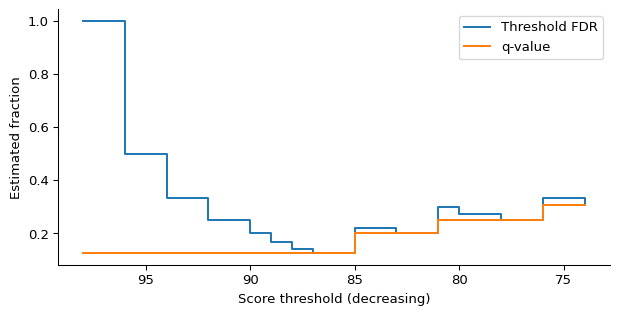

In [2]:
score = np.array([98, 96, 94, 92, 90, 89, 88, 87, 85, 85, 83, 81, 80, 78, 76, 74])
decoy = np.isin(np.arange(len(score)), [8, 11, 14])
s, f, q = qvalues(score, decoy)
assert np.all(np.diff(q) >= -1e-12) and np.all(q <= f + 1e-12)
print("score  estimate  q-value")
print(np.column_stack([s, f, q])[::2].round(3))
fig, ax = plt.subplots(figsize=(6.4, 3.2), constrained_layout=True)
ax.step(s, f, where="post", label="Threshold FDR")
ax.step(s, q, where="post", label="q-value")
ax.invert_xaxis()
ax.set(xlabel="Score threshold (decreasing)", ylabel="Estimated fraction")
ax.legend()
plt.show()

## Interpreting the result

A q-value applies to an accepted set under the target-decoy assumptions. Small numbers produce coarse estimates.

## Exercise

Remove the +1 and compare the first threshold with zero decoy wins.

## References

[Elias and Gygi, target-decoy search (2007)](https://doi.org/10.1038/nmeth1019)